In [1]:
using CSV
using DataFrames
using ROC
using Plots
using LaTeXStrings

In [3]:
# Set the data  directory to the parent directory of the script
wdir = dirname(@__DIR__)
cd(wdir)

In [ ]:
include("src/score.jl")
include("src/misc.jl")

In [60]:
variant="H3N2"
protein="NA"
year="2015"
directory_path = "data/$variant/$protein/results"
T0=observation_time(variant,protein,year);

In [33]:
pattern = r"simulation_results.*"
matching_files = filter(x -> occursin(pattern, x), readdir(directory_path))[1]
df_=DataFrame(CSV.File("$(directory_path)/$(matching_files)"));

In [62]:
# For plots
base = 12
lfs = base # Legend font size
alfs = base # axis label font size
tfs = base # title font size
atfs = base # axis ticks font size
ga = 0.3 # grid alpha
sizes =(450,400) # standard size for single plots
rl = 0.065 # position of the "A" or "B" label in % 
ms = 6 # marker size
ls = 6 # line size
annfs = 34;
#

In [58]:
# Compute fixation probability for each observation frequency
delta = 0.05
porcentage = 0.5

fix_prob_score_top = []
fix_prob_score_bottom = []
fix_prob_frequency = []

# Iterate over observation frequencies
for f0 in 0.1:0.1:0.9
    # Select trajectories with frequencies close to f0 at the end time
    df_selected = df_[(f0 + delta) .> last.(parse_string.(df_.Frequency)) .>= (f0 - delta), :]

    # Filter trajectories based on observation time
    df_selected = df_selected[df_selected.Time .> T0, :]

    # Remove trajectories that remain polymorphic at the end of the future trajectory
    df_selected = df_selected[(df_selected.Fixation .== "lost") .| (df_selected.Fixation .== "fixed"), :]

    # Calculate the number of fixed trajectories
    num_fix_tr = size(df_selected[(df_selected.Fixation .== "fixed"), :], 1)

    #  Compute simulations score 
    scores_simulations = score_simulations(df_selected)
    #calculate the total number of trajectories
    num_tr = size(scores_simulations, 1)

    # Calculate the number of first %percentage predictions 
    predictions = Int(round(porcentage * num_tr))

    # Compute fixation probabilities
    push!(fix_prob_score_top, sum(scores_simulations[1:predictions, 3]) / predictions)
    push!(fix_prob_score_bottom, sum(scores_simulations[predictions+1:end, 3]) / (num_tr - predictions))
    push!(fix_prob_frequency, sum(scores_simulations[1:end, 3]) / num_tr)
end


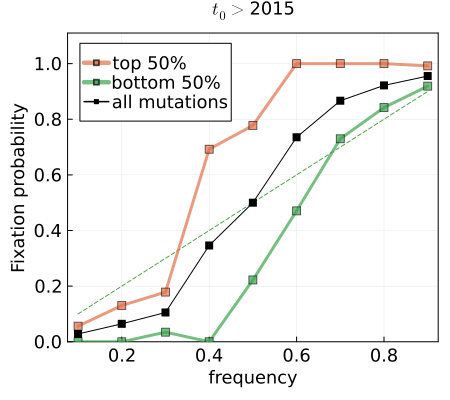

In [59]:
p=Plots.plot(0.1:0.1:0.9,0.1:0.1:0.9,line=:dash,color=:green,alpha=0.7,label="")
Plots.plot!(0.1:0.1:0.9,fix_prob_score_top,marker=:square,line=3,alpha=0.7,label="top 50%")
Plots.plot!(0.1:0.1:0.9,fix_prob_score_bottom,marker=:square,line=3,alpha=0.7,label="bottom 50%")
Plots.plot!(0.1:0.1:0.9,fix_prob_frequency,xlabel="",ylabel="",color=:black,marker=:square,label="all mutations")


plot!(p,tickfontsize=tfs, legendfontsize=lfs, guidefontsize=alfs,titlefontsize=alfs)
plot!(p,title=L"t_0 > " * year,frame=:box,fmt=:svg,ylim=[-0.0,1.11])
plot!(p, size=sizes)
xaxis!(p,0.0:0.2:1.0)
yaxis!(p,0.0:0.2:1.0)
#annotate!(p, 0.1, 1.0, text("A", annfs))

xlabel!("frequency")
ylabel!("Fixation probability")